In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/twitter_training.csv', header=None)

df.columns = ['ID', 'Topic', 'Sentiment', 'Tweet']

df.head()


,ID,Topic,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [3]:

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df['Sentiment'].value_counts())


Dataset Shape: (74682, 4)

Missing Values:
ID             0
Topic          0
Sentiment      0
Tweet        686
dtype: int64

Sentiment Distribution:
Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64


In [4]:

print("Before Cleaning:", df.shape)

df = df.dropna(subset=['Tweet'])

df = df.drop_duplicates()
print("After Cleaning:", df.shape)

print(df.isnull().sum())


Before Cleaning: (74682, 4)
After Cleaning: (71656, 4)
ID           0
Topic        0
Sentiment    0
Tweet        0
dtype: int64


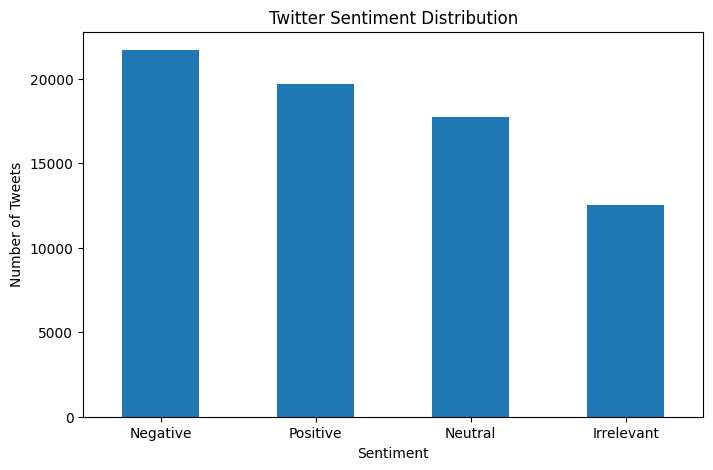

In [5]:

sentiment_count = df['Sentiment'].value_counts()

sentiment_count.plot(kind='bar', figsize=(8, 5))

plt.title('Twitter Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)

plt.show()


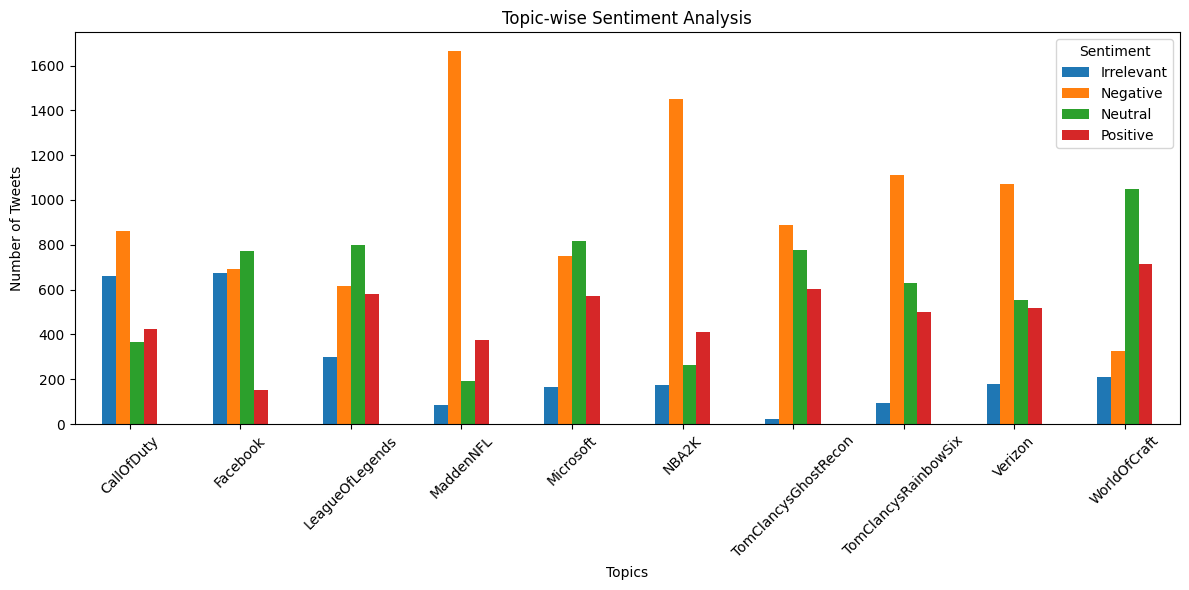

In [6]:

# Select top 10 topics
top_topics = df['Topic'].value_counts().head(10).index

# Compare sentiment by topic
data = df[df['Topic'].isin(top_topics)]

pd.crosstab(data['Topic'], data['Sentiment']).plot(
    kind='bar', figsize=(12, 6)
)

plt.title('Topic-wise Sentiment Analysis')
plt.xlabel('Topics')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()


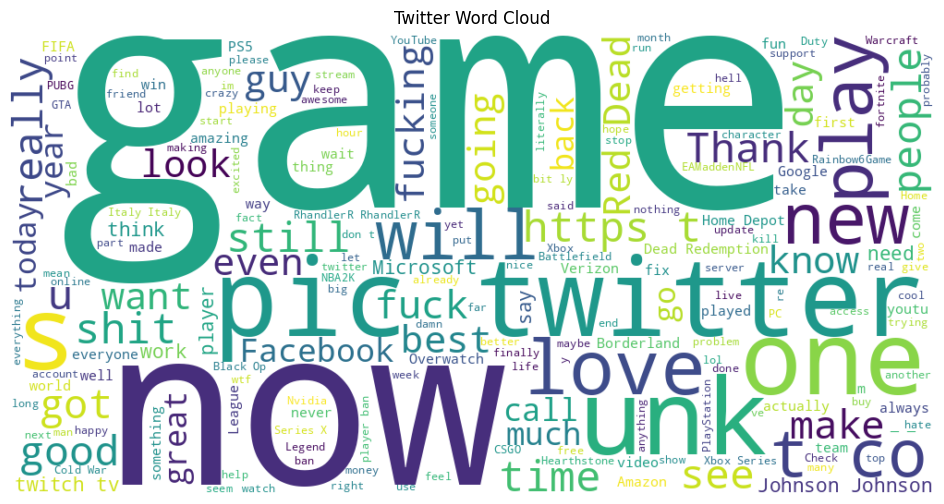

In [7]:

from wordcloud import WordCloud

# Combine all tweets
text = " ".join(df['Tweet'].astype(str))

# Create word cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(text)

# Display word cloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Twitter Word Cloud')
plt.show()



## **Results and Observations**

1. The dataset initially contained 74,682 tweets with four columns.
2. Data cleaning reduced the dataset to 71,556 records with no missing values.
3. Negative tweets were the highest (22,542), followed by Positive (20,832).
4. Neutral tweets accounted for 18,318 records, while Irrelevant tweets accounted for 12,990.
5. Topic-wise analysis showed differences in public sentiment across different brands and games.
6. The Word Cloud highlighted frequently used words in social media conversations.

## **Conclusion**

Sentiment analysis helped identify public opinions and attitudes towards different topics and brands on social media. Visualizations such as bar charts, topic-wise comparisons and Word Clouds made it easier to understand sentiment patterns. Data cleaning improved the quality of the dataset and helped produce more reliable results.
